# A small covariance experiment with Rafael's shear maps

**Thanks to Rafael Gomes for these CosmoGrid maps, and to Oliver Friedrich
and Tim Eifler for the [precision-matrix expansion](https://arxiv.org/abs/1703.07786).**
This experiment asks a limited but useful question: can a Gaussian reference
covariance describe the second- and third-order fluctuations measured from
these maps closely enough to attempt a precision expansion?

We measure coarse aperture moments, then compare a fixed Gaussian reference,
a simulation correction, and a separate validation sample. The reference
uses an aperture covariance estimated from a third group of simulations.
Thus it is a **Gaussian moment calculation calibrated on separate maps**,
not the independent analytic CosmoLike covariance we ultimately want to
correct. A successful test here would not calibrate the DES likelihood.

Follow [EXAMPLE_COVARIANCE_PME.ipynb](EXAMPLE_COVARIANCE_PME.ipynb) first for
the two-by-two noisy-square calculation. The
[notes](notes/covariance_from_simulations/covariance_from_simulations.pdf)
derive its assumptions. Here the inputs are real simulated shear fields,
but the measurement is intentionally much smaller than Rafael's published
xi/finite-triangle Map3 estimator.

The earlier split-group experiments below are historical diagnostics. The
current [report for Rafael](notes/covariance_comparison/covariance_comparison.pdf)
and its companion use the complete sample for each covariance comparison.

## 1. Measure once; study the small saved table repeatedly

Run this bounded pilot from Cocoa. It reads four noise labels, cut zero,
and at most 48 run labels. It measures all four source-bin slots:

```bash
python projects/des_3pcf/scripts/measure_covariance_maps.py --max-runs 48
```

Once the download has settled, this separate command applies **the same
pilot measurement** to every complete map currently present:

```bash
python projects/des_3pcf/scripts/measure_covariance_maps.py --all
```

The driver limits OpenMP to four and BLAS to one, opens one map at a time,
and writes small text tables under `chains/`. It does not copy the map files,
create per-map plots, or run the full three-point correlation estimator.
A file whose size or timestamp changes is deferred. A settled local file
is not a producer-certified file; input checksums and release metadata are
still needed. The covariance analysis reads only those measured tables. The final bounded
input check additionally reads 8,192 pixel positions from twenty files of
each of two run labels, to investigate what changes between noise labels.

In [1]:
# Setup only: this cell loads the plotting and statistical routines.
# No DES map, cosmological model or covariance calculation is started here.
# Run this notebook from the des_3pcf directory so the paths below refer to
# this checkout rather than another project's compiled interface.
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import os
from pathlib import Path
import sys
import importlib

# Set workers before importing NumPy. This small example needs one worker;
# BLAS must remain single-threaded in the Cocoa workflow.
for variable in (
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS",
    "BLIS_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
    "OMP_NUM_THREADS",
):
    os.environ[variable] = "1"
PROJECT = Path.cwd()
if not (PROJECT / "README.md").is_file():
    raise ValueError("Use des_3pcf as this notebook's working directory.")
CORE = PROJECT.parents[1] / "external_modules" / "code" / "cosmolike_core"
sys.path.insert(0, str(PROJECT / "interface"))
sys.path.insert(0, str(PROJECT / "scripts"))
sys.path.insert(0, str(CORE))
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
from threadpoolctl import threadpool_info, threadpool_limits
import cosmolike_des_3pcf_precision_wrappers as nw

# A notebook kernel may already have imported a BLAS library. Limit those
# loaded libraries too; environment variables alone would not change them.
blas_limit = threadpool_limits(limits=1, user_api="blas")
for library in threadpool_info():
    if library["user_api"] == "blas" and library["num_threads"] != 1:
        raise RuntimeError("A loaded BLAS library has more than one worker.")
# The shared plotting package accepts ordinary arrays and does not run
# this project's native interface. Its name begins with a digit, so importlib
# loads it by its full module name.
plots = importlib.import_module(name="cosmolike_notebook_utils.3pcf")

In [2]:
# Figure style of the whole notebook: the shared plotting functions never change
# rcParams, so these lines set every font, tick and grid default.
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams["figure.dpi"] = 90

In [3]:
# Read the completed all-map diagnostic table. Choosing covariance_maps_pilot
# instead replays the first 192-file sample. This cell never measures a map.
MEASUREMENT = PROJECT / "chains" / "covariance_maps_full"
map_vectors = np.loadtxt(fname=MEASUREMENT / "moments.txt", ndmin=2)
primary_apertures = np.loadtxt(
    fname=MEASUREMENT / "primary_apertures.txt",
    ndmin=2,
)
# Sorting by IDs also handles a later pass appending newly arrived files.
map_order = np.lexsort((map_vectors[:, 2], map_vectors[:, 1], map_vectors[:, 0]))
map_vectors = map_vectors[map_order]
primary_order = np.argsort(a=primary_apertures[:, 0])
primary_apertures = primary_apertures[primary_order]
centers = np.loadtxt(fname=MEASUREMENT / "centers.txt", ndmin=2)
print((MEASUREMENT / "measurement.txt").read_text())
print("Saved moment table shape:", map_vectors.shape)
print("Retained radial filter weight, minimum at each radius:",
      np.min(a=centers[:, 3:], axis=0))
# IDs are the first three columns. The remaining 16 columns are measurements.
run_ids = map_vectors[:, 0].astype(int)
cut_ids = map_vectors[:, 1].astype(int)
draw_ids = map_vectors[:, 2].astype(int)
values = map_vectors[:, 3:]
assert values.shape[1] == 16
assert np.all(np.isfinite(values))

Selected files: 15997
Measured files: 15997
Newly measured in this pass: 66
Deferred files: 0
Elapsed seconds (this pass): 4.390
OpenMP limit: 4
BLAS workers: 1
Pixel convention: RING/equatorial, geometry inference
Shear basis: g1 east, g2 +45deg toward north, UNCONFIRMED
Parent IDs: run labels, independence UNCONFIRMED
Q radii: 30,60 arcmin; truncated at 4R; 64 fixed centers
Rows: 8 raw squared moments then 8 raw cubed moments
No noise self-product subtraction; no catalogue weights
These are diagnostic moments, not the published xi/Map3 estimator.

Saved moment table shape: (15997, 19)
Retained radial filter weight, minimum at each radius: [0.98785809 0.98868762]


## 2. What did the driver measure?

Around each of 64 fixed centers, tangential shear is integrated with a
Gaussian aperture filter. Its radius $R$ is either 30 or 60 arcminutes:

$$Q_R(\theta)=\frac{\theta^2}{4\pi R^4}
\exp\!\left(-\frac{\theta^2}{2R^2}\right).$$

Angles in the calculation are in radians. Each retained HEALPix pixel
contributes its equal solid angle and its tangential shear:

$$a_{bRc}=\Omega_\mathrm{pix}\sum_{j\,\in\,\mathrm{retained}} Q_R(\theta_{cj})\,\gamma_{t,bj;c}.$$

Here $b$ labels a source-bin slot, $c$ a center, and $j$ a pixel. The bearing
used to rotate the shear is measured **at the pixel toward the center**.
The integral stops at four radii, retaining about 99.698% of the radial
weight in the unmasked flat-sky formula. Centers are chosen using geometry
alone and must retain at least 99% of that truncated weight at both radii.
The code does not renormalize away missing sky.

Average the squared aperture values over the same centers:

$$d_{2,bR}=\frac1{64}\sum_{c=1}^{64}a_{bRc}^2.$$

Separately average their cubes:

$$d_{3,bR}=\frac1{64}\sum_{c=1}^{64}a_{bRc}^3.$$

Four source bins and two radii give eight second-order entries and eight
third-order entries. Their covariance includes all cross-bin and
second/third-order cross-correlations.

**Measurement limits.** These raw moments retain pixel-noise self-products.
They use equal pixel weights, only 64 centers, and auto-bin moments. They
are not the catalogue pair/triple estimator, and they do not include the
published triangle cuts or all mixed-bin Map3 entries. The RING ordering is
supported by geometry. The assumed equatorial shear signs and the meaning
of run/cut/noise labels still need producer confirmation. NSIDE 512 differs
from the methods paper's NSIDE 1024. These choices remain fixed throughout
this diagnostic; none was adjusted to improve the covariance comparison.

## 3. Separate reference, correction, and validation parents

For the first precision test we use only cut zero, draw zero of each run.
No number of additional noise files increases this independent-parent count.
We assign runs by their integer ID modulo three **before inspecting the
results**. Remainder zero calibrates the Gaussian reference; remainder one
estimates its correction; remainder two validates it. All descendants of a
run retain that assignment.

This is a conditional statistical interpretation: different run labels must
really be independent parent simulations for the independence claims to
hold. Filename differences alone do not prove it. The other cuts are saved,
but do not enter this primary test as extra independent skies.

In [4]:
# Each parent contributes exactly one noisy survey vector in this test.
primary_selection = (cut_ids == 0) & (draw_ids == 0)
primary_runs = run_ids[primary_selection]
primary_vectors = values[primary_selection]
assert np.unique(primary_runs).size == primary_runs.size
np.testing.assert_array_equal(primary_apertures[:, 0].astype(int), primary_runs)
reference_selection = primary_runs % 3 == 0
correction_selection = primary_runs % 3 == 1
validation_selection = primary_runs % 3 == 2
reference_values = primary_vectors[reference_selection]
correction_values = primary_vectors[correction_selection]
validation_values = primary_vectors[validation_selection]
reference_apertures = primary_apertures[reference_selection, 1:]
print("Reference parents:", np.count_nonzero(reference_selection))
print("Correction parents:", np.count_nonzero(correction_selection))
print("Validation parents:", np.count_nonzero(validation_selection))
print("Rows:", primary_vectors.shape[1])
# Center each sample using its own mean. np.cov divides by N-1 here.
correction_covariance = np.cov(m=correction_values, rowvar=False, ddof=1)
validation_covariance = np.cov(m=validation_values, rowvar=False, ddof=1)

Reference parents: 67
Correction parents: 67
Validation parents: 66
Rows: 16


## 4. Build a Gaussian reference with the actual aperture geometry

Let $K_{ij}$ be the covariance of two aperture values. Its indices include
source bin, radius, and center. We estimate this matrix using only the
reference parents. A Gaussian field has no connected four- or six-point
correlations, so products of its aperture values reduce to sums of pairs.

For the squared measurements, subtracting the product of the two means
leaves two pairings:

$$\operatorname{Cov}(a_i^2,a_j^2)=2K_{ij}^2.$$

For the cubed measurements there are six pairings with all three factors
crossing between the two positions, and nine with one cross-pair:

$$\operatorname{Cov}(a_i^3,a_j^3)
 =6K_{ij}^3+9K_{ii}K_{jj}K_{ij}.$$

A squared measurement correlated with a cubed measurement contains five
zero-mean Gaussian factors. Their expectation vanishes:

$$\operatorname{Cov}(a_i^2,a_j^3)=0.$$

The moment covariance averages these expressions over **both** sets of
centers. Keeping all pairs accounts for overlapping apertures and their
correlations in this reference. Treating the 64 centers as independent
would drop these terms and would change the model.

This Gaussian reference omits connected non-Gaussian fluctuations. Its
input $K$ is estimated, so the reference also carries finite-calibration
noise and plug-in bias from powers of that estimate. It is held fixed and
independent of the correction and validation groups. Do not describe it as
a noise-free cosmological covariance or infer a simulation saving for the
production analysis from this experiment.

Gaussian-reference standard deviations: [6.23581163e-07 1.73943639e-07 8.08133150e-07 2.43282954e-07
 9.45765993e-07 3.28639091e-07 1.39459935e-06 4.70130101e-07
 2.04780202e-09 3.18021601e-10 3.33628181e-09 4.83323815e-10
 4.02373793e-09 7.34417099e-10 7.01151091e-09 1.25840949e-09]


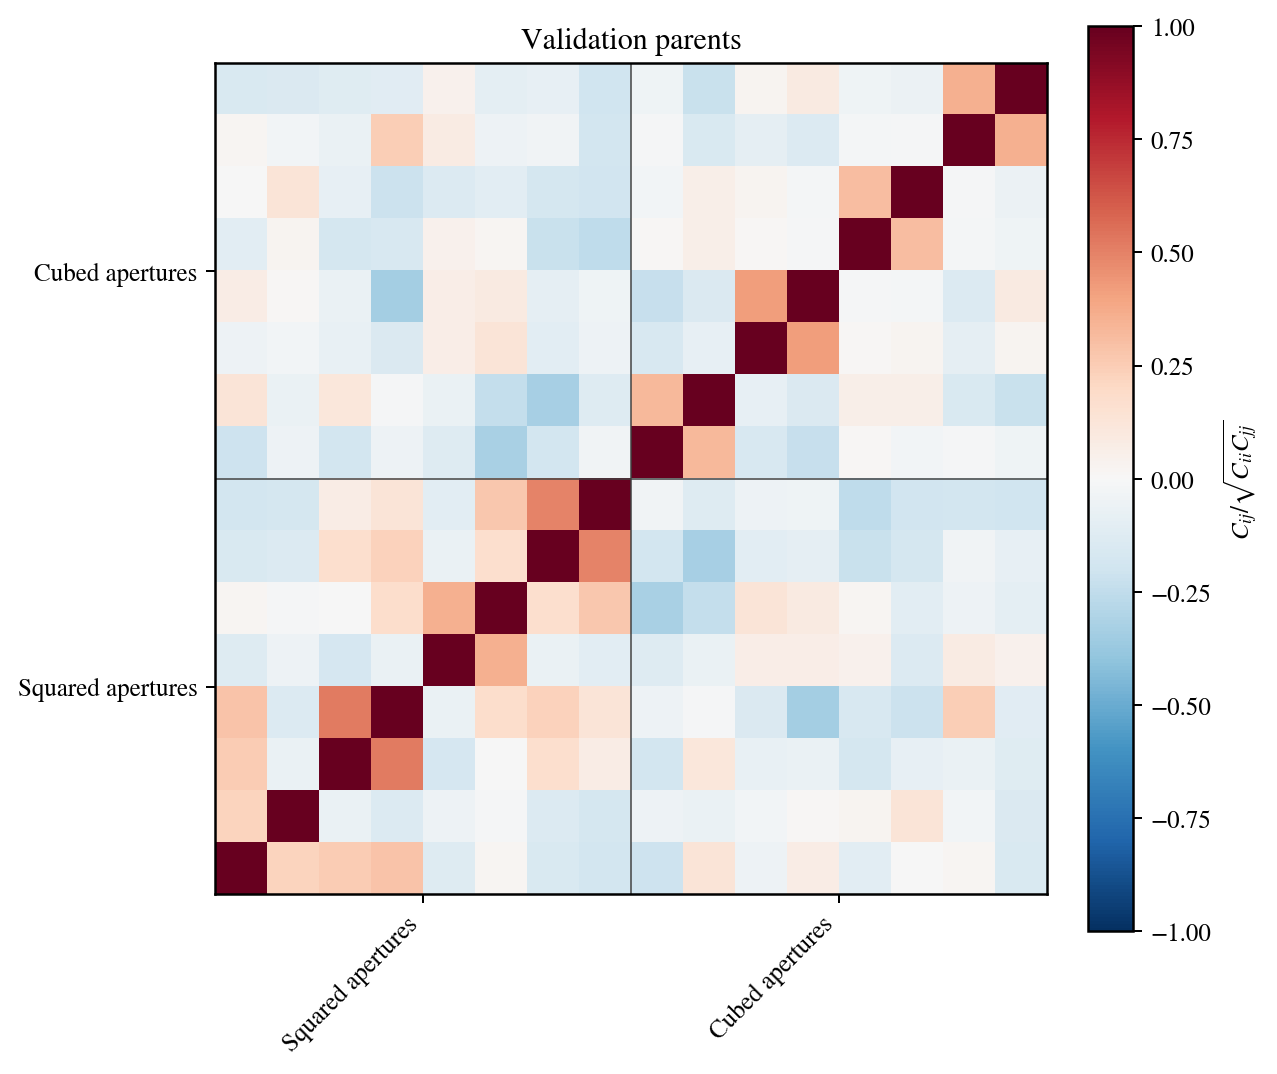

In [5]:
# The 512 aperture columns are ordered as [4 sources, 2 radii, 64 centers].
# Their sample covariance has blocks of 64 by 64 center correlations.
aperture_covariance = np.cov(m=reference_apertures, rowvar=False, ddof=1)
gaussian_model = np.zeros(shape=(16, 16))
for first_row in range(8):
    first_slice = slice(64 * first_row, 64 * (first_row + 1))
    first_variances = np.diag(v=aperture_covariance)[first_slice]
    for second_row in range(8):
        second_slice = slice(64 * second_row, 64 * (second_row + 1))
        second_variances = np.diag(v=aperture_covariance)[second_slice]
        cross = aperture_covariance[first_slice, second_slice]
        # These powers are ELEMENTWISE Gaussian pair contractions, not the
        # matrix square used in the PME correction. The final mean sums over
        # both centers and divides by 64 squared.
        gaussian_model[first_row, second_row] = 2. * np.mean(a=cross**2)
        one_cross_pair = 9. * np.outer(first_variances, second_variances) * cross
        three_cross_pairs = 6. * cross**3
        gaussian_model[first_row + 8, second_row + 8] = np.mean(
            a=one_cross_pair + three_cross_pairs,
        )
print("Gaussian-reference standard deviations:", np.sqrt(np.diag(gaussian_model)))
# The square/cube cross block is zero only in the reference. It is retained
# in both measured covariances and can therefore expose missing physics.
plots.plot_correlation(
    covariance=validation_covariance,
    labels=["Validation parents", "Reference"],
    block_sizes=[8, 8],
    block_labels=["Squared apertures", "Cubed apertures"],
)

## 5. Inspect the model discrepancy before trusting a correction

Whiten the covariance using the Gaussian reference. An eigenvalue of one
means the same variance as the reference in that direction. The residual
subtracts one. For the **true** covariance the inverse series needs every
residual eigenvalue between minus one and plus one.

Here both correction and validation eigenvalues are noisy sample estimates.
They diagnose a possible model failure; they do not prove convergence or
nonconvergence of the unknown true series. In particular, a singular sample
necessarily has residual eigenvalues of minus one, even if its model is
accurate. Do not interpret sample rank deficiency as a physical instability.

Correction eigenvalue range: [0.17075263 2.31511252]
Validation eigenvalue range: [0.08502661 1.9311188 ]
Correction sample rank: 16


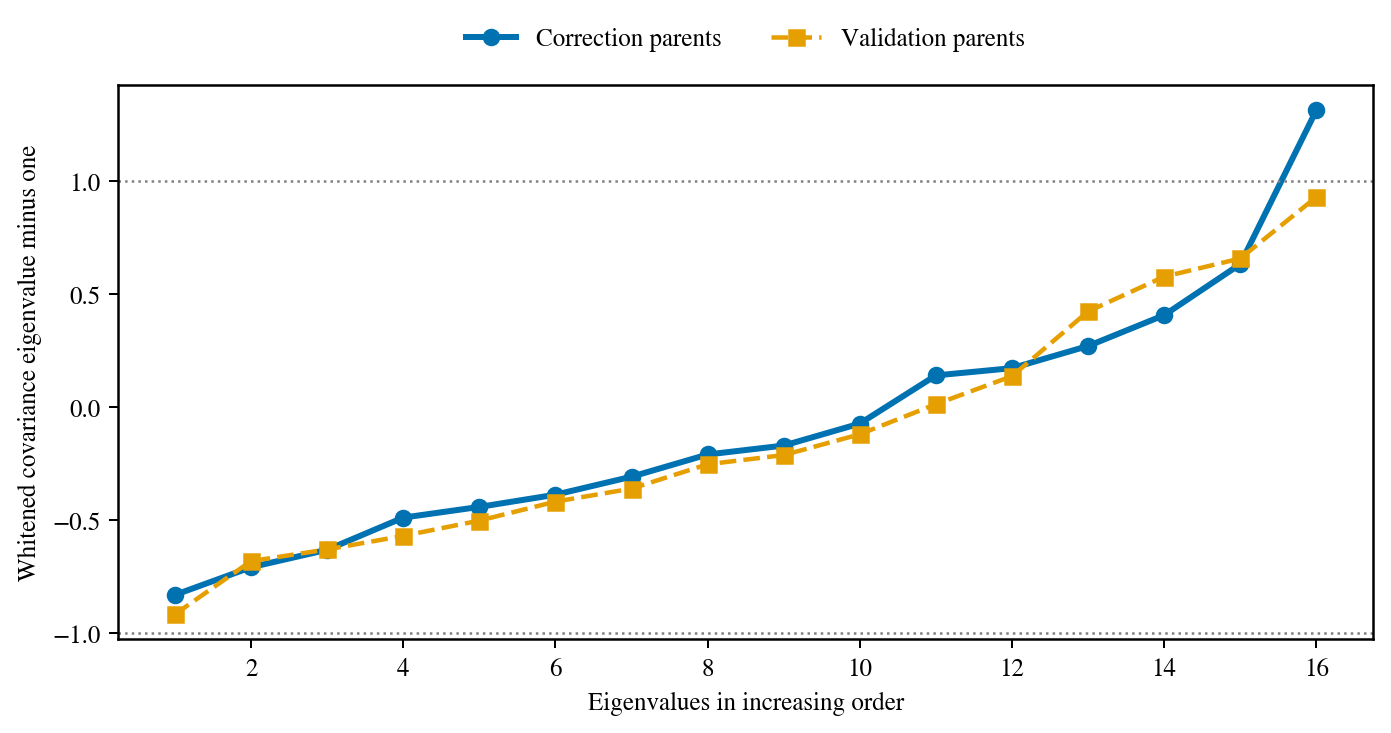

In [6]:
map_factor = np.linalg.cholesky(gaussian_model)
correction_whitened = nw.whiten_covariance(
    covariance=correction_covariance,
    factor=map_factor,
)
validation_whitened = nw.whiten_covariance(
    covariance=validation_covariance,
    factor=map_factor,
)
correction_eigenvalues = np.linalg.eigvalsh(correction_whitened)
validation_eigenvalues = np.linalg.eigvalsh(validation_whitened)
print("Correction eigenvalue range:", correction_eigenvalues[[0, -1]])
print("Validation eigenvalue range:", validation_eigenvalues[[0, -1]])
print("Correction sample rank:", np.linalg.matrix_rank(correction_whitened))
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.arange(1, 17), correction_eigenvalues - 1.,
        color="#0072B2", marker="o", linewidth=2.4, label="Correction parents")
ax.plot(np.arange(1, 17), validation_eigenvalues - 1.,
        color="#E69F00", marker="s", linewidth=1.8, linestyle="--",
        label="Validation parents")
ax.axhline(y=1., color="0.5", linestyle=":", linewidth=1.)
ax.axhline(y=-1., color="0.5", linestyle=":", linewidth=1.)
ax.set_xlabel("Eigenvalues in increasing order")
ax.set_ylabel("Whitened covariance eigenvalue minus one")
# The legend occupies a separate strip above the axes, never the data area.
legend = ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02),
                   ncol=2, frameon=False)
fig.canvas.draw()
assert legend.get_window_extent().y0 > ax.get_window_extent().y1
plt.show()

## 6. Apply the noisy-square correction to the training covariance

We now repeat the operations taught in the small notebook: square the
whitened covariance by matrix multiplication, compute its trace, subtract
the Wishart bias term, and restore precision units. The shared routine
performs those steps. The Gaussian-summary assumption is provisional for
these nonlinear moments; we also calculate the independent-group product.

No validation vector enters a correction. No negative eigenvalue is clipped.
A nonpositive precision is reported as unsuitable for likelihood weighting.
Even a positive result still needs validation.

In [7]:
map_count = correction_values.shape[0]
map_precisions = {"Gaussian reference": np.linalg.solve(gaussian_model, np.eye(16))}
for order in (1, 2):
    estimate, diagnostics = nw.precision_expansion(
        analytic=gaussian_model,
        sample=correction_covariance,
        independent_count=map_count,
        order=order,
    )
    map_precisions[f"PME order {order}"] = estimate
    print("Order", order, diagnostics)
# The two halves are disjoint parents, not two noise draws of the same sky.
half = map_count // 2
first_half = np.cov(m=correction_values[:half], rowvar=False, ddof=1)
second_half = np.cov(m=correction_values[half:], rowvar=False, ddof=1)
map_precisions["Independent-group product"] = nw.split_precision_expansion(
    analytic=gaussian_model,
    sample_first=first_half,
    sample_second=second_half,
)
# Inspect positivity in dimensionless model coordinates, where unequal units
# of squared and cubed measurements cannot hide a negative direction.
for name, precision in map_precisions.items():
    polynomial = map_factor.T @ precision @ map_factor
    print(name, "minimum precision eigenvalue =", np.linalg.eigvalsh(polynomial)[0])

Order 1 {'estimated_residual_spectral_radius': 1.3151125168538043, 'minimum_polynomial_eigenvalue': -0.3151125168538047, 'independent_count': 67, 'order': 1}
Order 2 {'estimated_residual_spectral_radius': 1.3151125168538043, 'minimum_polynomial_eigenvalue': 0.37032648460177114, 'independent_count': 67, 'order': 2}
Gaussian reference minimum precision eigenvalue = 0.9999999999999992
PME order 1 minimum precision eigenvalue = -0.3151125168538047
PME order 2 minimum precision eigenvalue = 0.37032648460177114
Independent-group product minimum precision eigenvalue = -0.8407260850049812


## 7. Test the weights against untouched validation parents

For a fixed precision, a simple validation diagnostic is

$$q=\frac{\operatorname{tr}(\widehat\Psi\widehat C_\mathrm{val})}{p}.$$

The row count is $p=16$. The validation covariance uses its own estimated
mean and denominator $N_\mathrm{val}-1$, so its expectation is the true
covariance. Conditional on a fixed exact precision and independent parents,
the expected value of $q$ is one. Values above one indicate underestimated
fluctuations on average. Different directions can cancel in this trace;
$q$ near one does not establish correct parameter errors.

The uncertainty below removes one validation parent at a time, recomputes
the covariance and repeats the diagnostic. The jackknife standard error is

$$\sigma_q=\left[\frac{N_v-1}{N_v}\sum_{s=1}^{N_v}
 (q_{(-s)}-\bar q_{(-)})^2\right]^{1/2}.$$

Here $q_{(-s)}$ omits parent $s$, while the bar averages those results. This
measures sensitivity to the finite validation set with the precision held
fixed. It is not an exact confidence interval and does not include
reference-calibration noise, repeated training experiments, or a wrong
parent-independence assumption.

In [8]:
# Leaving out whole parents preserves the sky grouping. These calculations
# use only the small measured table, with the precision held fixed.
leave_one_out_covariances = []
for omitted in range(len(validation_values)):
    selected = np.arange(len(validation_values)) != omitted
    leave_one_out_covariances.append(
        np.cov(m=validation_values[selected], rowvar=False, ddof=1),
    )
print("Method | positive | validation q | jackknife standard error")
for name, precision in map_precisions.items():
    polynomial = map_factor.T @ precision @ map_factor
    positive = np.linalg.eigvalsh(polynomial)[0] > 0.
    q = np.trace(a=precision @ validation_covariance) / 16.
    leave_one_out = []
    for covariance in leave_one_out_covariances:
        leave_one_out.append(np.trace(a=precision @ covariance) / 16.)
    leave_one_out = np.asarray(leave_one_out)
    centered = leave_one_out - np.mean(a=leave_one_out)
    count = len(leave_one_out)
    jackknife_error = np.sqrt((count - 1.) / count * np.sum(a=centered**2))
    print(name, positive, f"{q:.4f}", f"{jackknife_error:.4f}")
# An indefinite result stays visible for diagnosis; its q does not validate
# a usable likelihood and must not be used to report parameter errors.

Method | positive | validation q | jackknife standard error
Gaussian reference True 0.8812 0.0487
PME order 1 False 0.8894 0.0578
PME order 2 True 0.9207 0.0550
Independent-group product False 0.8492 0.0549


## 8. What do the repeated noise draws buy us?

Keep cut zero throughout. Use the same number $K$ of measured noise draws
for each selected parent. Within parent $s$, compute the mean measured
vector and its sample covariance $W_s$. Average these covariances to obtain
$\widehat A$. Compute the covariance of the parent means separately.

A parent mean still contains noise covariance $A/K$. The covariance of one
noisy survey therefore follows the restoration derived in the teaching
notebook:

$$\widehat C=\widehat C_{\bar d}+(1-1/K)\widehat A.$$

We also inspect the difference estimating the sky contribution:

$$\widehat B=\widehat C_{\bar d}-\widehat A/K.$$

These use measured vectors, not averaged maps. A negative eigenvalue in
$\widehat B$ can arise from finite sampling; it does not license clipping it
or feeding it into the Wishart component formula. That formula requires a
genuine sample of an isolated component. For these raw nonlinear moments,
$B$ is the covariance of conditional means, not automatically the covariance
of noiseless Map3.

In [9]:
# Four shared draw labels make the pilot and full run comparable. The full
# run can also test K=20 by changing this visible choice, without reading maps.
noise_count = 4
parent_means = []
within_covariances = []
used_parents = []
for run in np.unique(run_ids):
    selected = (run_ids == run) & (cut_ids == 0) & (draw_ids < noise_count)
    draws = draw_ids[selected]
    if not np.array_equal(np.sort(draws), np.arange(noise_count)):
        continue
    parent_values = values[selected]
    parent_means.append(np.mean(a=parent_values, axis=0))
    within_covariances.append(np.cov(m=parent_values, rowvar=False, ddof=1))
    used_parents.append(run)
within_noise = np.mean(a=within_covariances, axis=0)
parent_mean_covariance = np.cov(m=parent_means, rowvar=False, ddof=1)
restored_covariance = parent_mean_covariance + (1. - 1. / noise_count) * within_noise
estimated_sky_covariance = parent_mean_covariance - within_noise / noise_count
noise_fraction = np.diag(within_noise) / np.diag(restored_covariance)
print("Parents with all selected draws:", len(used_parents))
print("K:", noise_count)
print("Within-parent variance / restored one-survey variance:\n",
      noise_fraction.reshape(2, 4, 2))
print("Axes of the preceding array: moment order [2,3], source bin, radius.")
sky_whitened = nw.whiten_covariance(
    covariance=estimated_sky_covariance,
    factor=map_factor,
)
print("Estimated sky-component minimum eigenvalue:", np.linalg.eigvalsh(sky_whitened)[0])

Parents with all selected draws: 200
K: 4
Within-parent variance / restored one-survey variance:
 [[[1.01563028 0.98964342]
  [1.00324708 0.97212081]
  [1.0032667  0.95926262]
  [0.98367511 0.9590406 ]]

 [[1.0047246  1.03165525]
  [1.02223518 0.94475215]
  [0.94232154 0.96673078]
  [0.91399191 0.94069987]]]
Axes of the preceding array: moment order [2,3], source bin, radius.
Estimated sky-component minimum eigenvalue: -0.11357397645038825


## 9. A bounded check of what changes between realization labels

The statistical interpretation needs evidence that different noise draws
retain the same sky. We inspect only runs zero and one, cut zero, and draws
zero through nineteen. For each map we select the same 8,192 pixel positions.
The full archive is not scanned by this cell.

If a map is a shared sky plus independent zero-mean noise, call their spatial
variance contributions $V_s$ and $V_n$. The expected variance of one draw is

$$V_\mathrm{one}=V_s+V_n.$$

The expected variance of the average of $K$ draws is smaller:

$$V_\mathrm{mean}=V_s+V_n/K.$$

Multiply this second expression by $K$ and subtract the first. The noise
terms cancel, giving the estimate

$$\widehat V_s=\frac{K\widehat V_\mathrm{mean}-\widehat V_\mathrm{one}}{K-1}.$$

We print its ratio to the average single-map variance. A result close to
zero means the selected components show little repeated spatial structure
under the supplied pixel ordering. It does not prove noise-only inputs:
weak common signal, changes to the sky between labels, or a different pixel
assignment can also matter. Small negative estimates are possible.
This check is unchanged by consistently flipping a shear component's sign.
It cannot establish the sign convention for a correlation estimator.

In [10]:
# This metadata investigation has a hard bound: 40 files and
# 8,192 common pixel positions in each. No maps or pixel samples are saved.
# The statistics are across pixels; their spatial correlations prevent
# treating 8,192 as a count of independent cosmological measurements.
probe_folder = PROJECT / "maps_cov_512_v2"
probe_pixels = np.linspace(0, 369190 - 1, 8192, dtype=int)
for run in (0, 1):
    pixel_sum = np.zeros(shape=(4, 2, len(probe_pixels)))
    variance_sum = np.zeros(shape=(4, 2))
    for draw in range(20):
        filename = f"ShearMaps_DESY3_run_{run:04d}_ncut0_nreal{draw}.npy"
        mapped = np.load(file=probe_folder / filename, mmap_mode="r")
        sampled_pixels = np.array(mapped[:, :, probe_pixels])
        del mapped
        pixel_sum += sampled_pixels
        variance_sum += np.var(a=sampled_pixels, axis=2)
    one_variance = variance_sum / 20.
    mean_map = pixel_sum / 20.
    mean_variance = np.var(a=mean_map, axis=2)
    common_variance = (20. * mean_variance - one_variance) / 19.
    print("Run", run, "shared spatial variance / one-map variance:")
    print(common_variance / one_variance)
    print("Rows are source bins; columns are the two shear components.")
# The labels and signal/noise content still need producer confirmation.
# These numbers are a diagnostic of the available files, not that confirmation.

Run 0 shared spatial variance / one-map variance:
[[-8.22955373e-04 -1.79508603e-04]
 [ 6.01679388e-04  8.98153630e-04]
 [-4.35602292e-05  3.87817994e-04]
 [ 6.56669279e-04 -2.31081734e-04]]
Rows are source bins; columns are the two shear components.


Run 1 shared spatial variance / one-map variance:
[[-0.00059755  0.00172008]
 [ 0.00194874 -0.00049151]
 [ 0.00321931  0.00321003]
 [ 0.00297794  0.00256446]]
Rows are source bins; columns are the two shear components.


For run zero, these estimated shared fractions range from about −0.08% to
+0.09%; for run one, from about −0.06% to +0.32%. These are fractions of
**raw pixel variance**, not fractions of the aperture covariance. A small
spatially coherent signal can become more important after filtering, because
averaging suppresses independent pixel noise. The result is therefore a
reason to obtain the input metadata, not a demonstration that the maps
lack cosmological signal.

## 10. What would count as evidence for the production calculation?

The measurements above can establish that the map stream, parent grouping,
repeat-noise calculation, and matrix corrections are executable. They can
also reveal that this particular Gaussian starting point is inadequate.
They cannot establish accurate DES parameter errors, a simulation saving,
or the validity of the Gaussian-summary assumption for the final vector.

The next scientific test needs the same measured xi/Map3 rows and analytic
covariance: source populations, shape noise, mask, pixel smoothing,
normalization, and angular cuts must match. The analytic covariance should
include the connected and survey-scale terms needed to make its remaining
error small. Reserve parent skies for validation and check parameter-sensitive
directions, not just the trace. If the Gaussian reference fails here, the
useful response is to improve that reference and obtain a fresh validation
sample; increasing the correction order or clipping eigenvalues does not
repair its missing physics.

A calibration covariance estimated from these maps must be counted in the
simulation budget. The filename parent interpretation and the equatorial
shear signs still need Rafael's confirmation before a survey-level result.
The numerical output of this notebook is a diagnostic of the specified
coarse moments, with those assumptions kept visible.

**The first 48-run pilot did not validate a correction.** Sixteen parents in
each group gave a correction sample of rank 15 for 16 rows. First-order,
second-order, and split-product precisions all had negative eigenvalues.
The Gaussian reference's average validation weight was near one, but that
single trace did not fix the failed precision directions. Within-parent
variation accounted for almost all of the coarse moment variance. This
motivates checking the maps' signal/noise content; it does not establish that
Friedrich--Eifler fails for a matched cosmological covariance.

If the files contain **noise only**, they can help estimate the noise
contribution for a specified estimator, but cannot supply the missing
connected covariance of the cosmological signal. If they contain signal
plus noise, shared-sky tests should identify the repeated structure. Either
case requires recording what is randomized; a filename count cannot decide
which physical covariance has been measured.

**The completed local pass uses 200 primary run labels.** The fixed split
has 67 reference, 67 correction and 66 validation runs. Second-order PME is
now positive; its average validation weight is 0.9207 ± 0.0550, compared with
0.8812 ± 0.0487 for the reference. These are correlated diagnostics, with
jackknife errors for validation sampling only. The estimated residual
spectral radius is 1.315, above the unit-radius convergence condition; its
sampling uncertainty does not turn positivity into a convergence test.
First-order and split-product precisions remain indefinite. This is progress
in one diagnostic, not a calibrated cosmological precision matrix.

## 11. Use the released joint covariance as a comparison target

The project already contains Rafael's released 480-row covariance and its
paired measurements. Its rows are ordered as 200 xi-plus, 200 xi-minus, then
80 Map3 entries. The Map3 covariance block exactly matches the block in the
released Map3 measurement file. The standalone two-point covariance differs
from the joint file's two-point block; we therefore use the **joint file**
consistently for this comparison.

The joint FITS header records `NSIM=500`, while the selected upstream
analysis configuration and methods paper specify 796. These are conflicting
pieces of provenance. We record them and leave the input untouched. Do not
choose degrees of freedom for a covariance likelihood from that header
without resolving the conflict.

The released covariance is useful for checking the measurement's scale,
correlations, and row definitions. If it was estimated from the same parent
skies, agreement is **not independent validation**. Its own finite-sample
noise also remains. It cannot automatically become a noise-free reference
for the precision-expansion test.

In [11]:
from astropy.io import fits

released_data = PROJECT / "data" / "upstream_y3_observed" / "data"
joint_file = released_data / "covariance" / "xip_xim_map3_covariance_8ARCMINCUT_25Feb25.fits"
two_point_file = released_data / "dv" / "real_2pt_desy3_unblind_g2flip_matchElisa_2025Mar10.fits"
map3_file = released_data / "dv" / "real_map3_desy3_unblind_scalecut3pcf_796simcov_2025Mar11.fits"
with fits.open(name=joint_file, memmap=False) as hdus:
    released_covariance = np.array(hdus["COVMAT"].data)
    header_count = hdus["COVMAT"].header["NSIM"]
standalone_two_point = fits.getdata(filename=two_point_file, extname="COVMAT")
standalone_map3 = fits.getdata(filename=map3_file, extname="COVMAT")
print("Joint covariance shape:", released_covariance.shape)
print("FITS header NSIM:", header_count)
# Read the explicit override in the selected upstream configuration. This
# audit does not execute Cosmosis or resolve its other included parameters.
configuration = (PROJECT / "data" / "upstream_y3_observed" / "config"
                 / "unblind-metacal-796sims-february-Percival-2ptfix-3pcfsc"
                 / "unblind-metacal-shear-2pt-map3-NLA-all.ini")
configured_counts = []
for line in configuration.read_text().splitlines():
    stripped = line.strip()
    if stripped.startswith("covariance_realizations ="):
        configured_counts.append(int(stripped.split("=", 1)[1]))
assert len(configured_counts) == 1
print("Selected upstream configuration covariance_realizations:", configured_counts[0])
print("Map3 block is identical:",
      np.array_equal(released_covariance[400:, 400:], standalone_map3))
print("Standalone two-point block is identical:",
      np.array_equal(released_covariance[:400, :400], standalone_two_point))
standalone_ratio = np.diag(standalone_two_point) / np.diag(released_covariance)[:400]
print("Standalone/joint two-point variance ratio range:",
      np.min(a=standalone_ratio), np.max(a=standalone_ratio))

Joint covariance shape: (480, 480)
FITS header NSIM: 500
Selected upstream configuration covariance_realizations: 796
Map3 block is identical: True
Standalone two-point block is identical: False


Standalone/joint two-point variance ratio range: 0.8951201942964255 1.0915854485512557


## 12. Compare four actual xi-plus bins

The second measurement driver uses TreeCorr to count shear pairs in the
released angular bins for source-bin slot four. The selected joint rows are
192–195, spanning 39.622–99.527 arcminutes. Both pair-binning and shear-angle
approximation tolerances are zero. The first map also compares tree grouping
with brute-force pairs on a 2,048-pixel subset. This replaces an earlier
approximate-bin attempt whose numerical changes were too large for the
comparison.

Run the bounded measurement from Cocoa:

```bash
python projects/des_3pcf/scripts/measure_covariance_xip.py --runs 32
```

This optional driver requires TreeCorr 5.1.2, LSSTDESC.Coord 1.3.0 and
astropy-healpix. It uses three OpenMP workers, leaving one core for the map
stream, with BLAS at one. The notebook below only reads its small saved table.

TreeCorr's spherical shear basis points west/north. We use `flip_g2=True`
to implement the same east/north assumption as the coarse aperture pilot.
The first map also records the opposite sign; it does not select a preferred
convention by matching the covariance. All map pixels have equal weights,
which still needs comparison with the producer's weighting. These maps are
NSIDE 512; the methods paper describes 1024. Matching angular bin edges
therefore establishes only part of an estimator match.

For $N$ provisional parent surveys, subtract their mean and compute

$$\widehat C_{ij}=\frac{1}{N-1}\sum_s
 (d_{si}-\bar d_i)(d_{sj}-\bar d_j).$$

This estimates the fluctuations of **one survey**, which is what the
released covariance describes. Dividing it by $N$ would instead estimate
the covariance of the ensemble mean and would make the comparison wrong.

In [12]:
XIP_MEASUREMENT = PROJECT / "chains" / "covariance_xip_comparison"
print((XIP_MEASUREMENT / "measurement.txt").read_text())
xip_table = np.loadtxt(fname=XIP_MEASUREMENT / "xip.txt", ndmin=2)
xip_rows = np.loadtxt(fname=XIP_MEASUREMENT / "rows.txt", ndmin=2)
# Only the declared east/north assumption enters the sample covariance.
# The alternate sign for the first map is a convention check, not a new sky.
xip_sample = xip_table[xip_table[:, 1] == 1., 2:]
xip_parents = xip_table[xip_table[:, 1] == 1., 0].astype(int)
assert np.unique(xip_parents).size == len(xip_parents)
indices = xip_rows[:, 0].astype(int)
np.testing.assert_array_equal(indices, np.arange(192, 196))
xip_reference = released_covariance[np.ix_(indices, indices)]
xip_covariance = np.cov(m=xip_sample, rowvar=False, ddof=1)
variance_ratio = np.diag(xip_covariance) / np.diag(xip_reference)
xip_mean = np.mean(a=xip_sample, axis=0)
mean_standard_error = np.sqrt(np.diag(xip_covariance) / len(xip_sample))
print("Measured primary run labels:", xip_parents)
print("Mean xi-plus:", xip_mean)
print("Standard error of that mean:", mean_standard_error)
print("One-survey variance / released variance:", variance_ratio)
# Correlation differences remain in the matrix; the diagonal ratio alone
# cannot establish equality of the two covariance matrices.
xip_factor = np.linalg.cholesky(xip_reference)
xip_whitened = nw.whiten_covariance(
    covariance=xip_covariance,
    factor=xip_factor,
)
print("Covariance eigenvalues in released-model units:",
      np.linalg.eigvalsh(xip_whitened))
for flip in (0, 1):
    check = np.loadtxt(fname=XIP_MEASUREMENT / f"tree_check_flip{flip}.txt")
    print("Sign check", flip, "max tree/brute xi difference:",
          np.max(a=np.abs(check[:, 0] - check[:, 1])))

Parents: 32
Cut: 0
Draw: 0
Source-bin slot: 4
TreeCorr version: 5.1.2
OpenMP: 3
BLAS: 1
Weights: equal per retained pixel; producer weights unavailable
Tree approximations: bin_slop=0 angle_slop=0; 2048-pixel tree/brute check
Metric: Arc
NSIDE: 512
Pixel ordering: RING inferred from footprint
Signs: first map both signs; main sample flip_g2=True (assumed east/north)
Bins: released xi-plus rows 192..195, 39.622..99.527 arcmin
No catalogue-noise covariance from TreeCorr is used
Released matrix may share parent simulations; this is a consistency check
Cross tests: 8 same-run draw pairs and disjoint different-run pairs
Elapsed seconds: 502.265

The cross-route positive and direct-pair controls were run additionally.
The 502.265-second record covers the original primary and eight-pair run.

Measured primary run labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31]
Mean xi-plus: [7.16869147e-06 5.79657858e-06 4.43694802e-06 3.05194156e-06]

The bars below measure sensitivity to leaving out one parent at a time.
They describe uncertainty in our small measured sample; they omit noise in
the released reference and any dependence from shared parent skies. The
line at one marks equal variances for a single survey. A disagreement calls
for checks of resolution, weights, shear conventions, and simulation
content before interpreting it as a failure of covariance physics.

Even agreement would establish consistency for four two-point rows only.
The Map3 and cross-covariance blocks still require the published triangle
measurement and scale cuts. No precision correction or Fisher constraint is
computed from this comparison.

Variance-ratio jackknife standard errors: [0.3723697  0.42048988 0.44524493 0.28075769]


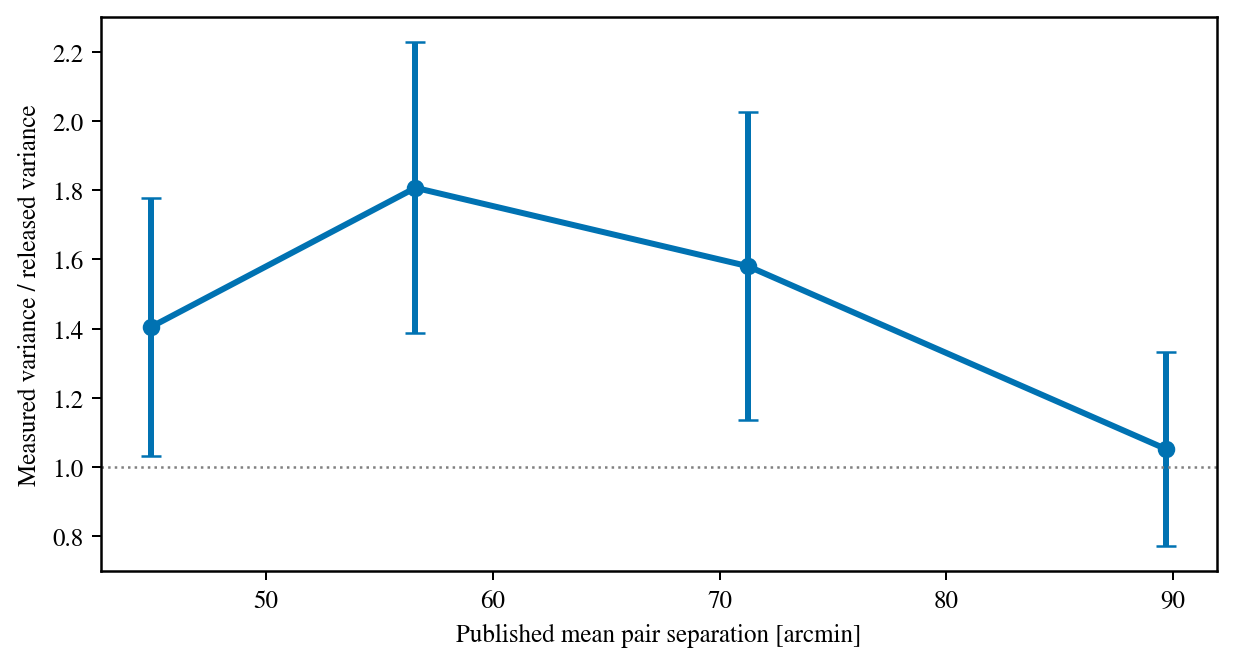

In [13]:
# These small jackknife calculations reuse the measured vectors only.
leave_one_out = []
for omitted in range(len(xip_sample)):
    selection = np.arange(len(xip_sample)) != omitted
    covariance = np.cov(m=xip_sample[selection], rowvar=False, ddof=1)
    leave_one_out.append(np.diag(covariance) / np.diag(xip_reference))
leave_one_out = np.asarray(leave_one_out)
centered = leave_one_out - np.mean(a=leave_one_out, axis=0)
count = len(xip_sample)
ratio_standard_error = np.sqrt((count - 1.) / count * np.sum(a=centered**2, axis=0))
print("Variance-ratio jackknife standard errors:", ratio_standard_error)
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(x=xip_rows[:, 3], y=variance_ratio, yerr=ratio_standard_error,
            color="#0072B2", marker="o", linewidth=2.4, capsize=4)
ax.axhline(y=1., color="0.5", linestyle=":", linewidth=1.)
ax.set_xlabel("Published mean pair separation [arcmin]")
ax.set_ylabel("Measured variance / released variance")
plt.show()

## 13. Does changing the realization label preserve the shear signal?

A correlation between *different* noise draws can answer a question that
pixel variance alone cannot. Suppose the two maps contain the same sky
signal, $s$, and independent noise fields:

$$g^{(0)}=s+n^{(0)}.$$

The second map is

$$g^{(1)}=s+n^{(1)}.$$

For this explanation, read the following product as either scalar component
of the properly rotated shear pair. Expand it before taking an average:

$$g^{(0)}_i g^{(1)}_j
=s_i s_j+s_i n^{(1)}_j+n^{(0)}_i s_j+n^{(0)}_i n^{(1)}_j.$$

If each noise field has conditional mean zero and the two fields are
independent at fixed sky, the last three terms have zero expectation. The
cross-correlation therefore retains the shared sky signal:

$$\mathbb{E}[g^{(0)}_i g^{(1)}_j\mid s]=s_i s_j.$$

At nonzero separation, the same-map correlation also estimates that signal
if the within-map noise has no correlation between distinct pixels. This
last condition must be stated: correlated noise can survive a same-map
measurement. A comparison between different independent skies has zero
ensemble expectation, provided their mean shear is zero.

The driver tests eight same-run pairs (draw zero against draw one), with
runs 0–7. Its control pairs those runs with runs 8–15, using draw zero in
both. All pairs use the same four exact angular bins and source-bin slot
four. This is a bounded diagnostic, not a replacement for the producer's
metadata. The four angular points are correlated; do not interpret them as
four independent detections. Error bars below are standard errors across
eight pairs, conditional on the run labels identifying independent skies.

Paired run labels: [0 1 2 3 4 5 6 7]
Same-run cross minus auto, in units of 1e-6: [-6.83031104 -5.62317479 -4.14217592 -3.30359751]
Standard error of that paired difference, in units of 1e-6: [0.48189759 0.39811453 0.33378138 0.27577426]
Same map mean in units of 1e-6: [6.66017328 5.73154053 4.08204228 3.22477877]
Same map standard error in units of 1e-6: [0.34129513 0.40175141 0.23916788 0.18752039]
Different draw, same run mean in units of 1e-6: [-0.17013776  0.10836574 -0.06013363 -0.07881873]
Different draw, same run standard error in units of 1e-6: [0.26141942 0.23175443 0.24913458 0.16806279]
Different run mean in units of 1e-6: [ 0.27151875 -0.10032067  0.20725485 -0.08756649]
Different run standard error in units of 1e-6: [0.16336948 0.30818003 0.16998511 0.18933952]


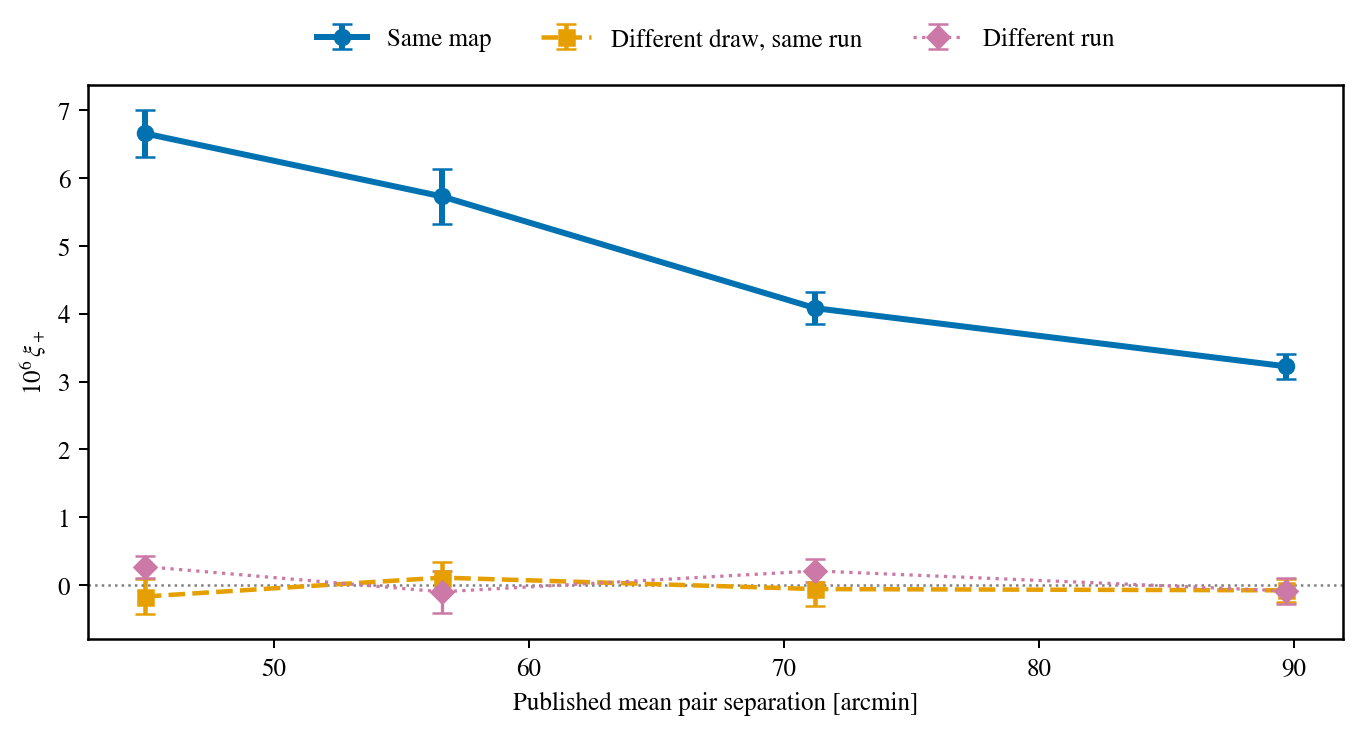

In [14]:
# Each row identifies both maps before listing the four cross-correlations.
# The first two columns let us separate same-run tests from different-run
# controls without inferring their meanings from row order.
cross_table = np.loadtxt(fname=XIP_MEASUREMENT / "cross_xip.txt", ndmin=2)
same_selection = cross_table[:, 0] == cross_table[:, 1]
same_cross = cross_table[same_selection, 3:]
different_cross = cross_table[~same_selection, 3:]
paired_runs = cross_table[same_selection, 0].astype(int)
assert len(np.unique(paired_runs)) == len(paired_runs)
auto_selection = np.isin(element=xip_parents, test_elements=paired_runs)
auto_pairs = xip_sample[auto_selection]
np.testing.assert_array_equal(xip_parents[auto_selection], paired_runs)
assert same_cross.shape == different_cross.shape == auto_pairs.shape

# Compare the SAME primary runs in the auto and within-run curves. This
# removes the unnecessary variation from choosing a different sky sample.
# The different-run control still has finite fluctuations about zero.
paired_difference = same_cross - auto_pairs
print("Paired run labels:", paired_runs)
print("Same-run cross minus auto, in units of 1e-6:",
      1.e6 * np.mean(a=paired_difference, axis=0))
print("Standard error of that paired difference, in units of 1e-6:",
      1.e6 * np.std(a=paired_difference, axis=0, ddof=1) / np.sqrt(len(paired_runs)))
fig, ax = plt.subplots(figsize=(9, 4))
for sample, name, color, marker, width, style in (
    (auto_pairs, "Same map", "#0072B2", "o", 2.4, "-"),
    (same_cross, "Different draw, same run", "#E69F00", "s", 1.8, "--"),
    (different_cross, "Different run", "#CC79A7", "D", 1.3, ":"),
):
    mean = np.mean(a=sample, axis=0)
    standard_error = np.std(a=sample, axis=0, ddof=1) / np.sqrt(len(sample))
    print(name, "mean in units of 1e-6:", 1.e6 * mean)
    print(name, "standard error in units of 1e-6:", 1.e6 * standard_error)
    ax.errorbar(
        x=xip_rows[:, 3],
        y=1.e6 * mean,
        yerr=1.e6 * standard_error,
        color=color,
        marker=marker,
        linewidth=width,
        linestyle=style,
        capsize=4,
        label=name,
    )
ax.axhline(y=0., color="0.5", linestyle=":", linewidth=1.)
ax.set_xlabel("Published mean pair separation [arcmin]")
ax.set_ylabel(r"$10^6\,\xi_+$")
legend = ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=3,
    frameon=False,
)
fig.canvas.draw()
assert legend.get_window_extent().y0 > ax.get_window_extent().y1
plt.show()

The same-run cross signal is consistent with zero at these angles, while
the same-map signal is clearly positive. Under a fixed aligned sky plus
independent, uncorrelated pixel noise, they should agree in expectation.
The observed difference challenges that interpretation of `nreal`; the actual
randomization still requires the producer's information. We cannot call the
within-run covariance in Section 8 a shape-noise covariance on filename
information alone.

The separate [comparison note](notes/covariance_comparison/covariance_comparison.pdf)
and its [notebook](notes/covariance_comparison/EXAMPLE_COVARIANCE_COMPARISON.ipynb)
include the cross-route positive control, direct pair checks and compact
recorded measurements. Those tests reproduce the released-covariance
comparison without the full map archive.

## 14. Use 150 correction runs and hold out the remaining 50

This is a separate test using the **16 coarse aperture moments**, not the
four xi-plus bins in the released-covariance comparison. We hold the
previous reference matrix fixed and increase only the correction sample.
The small recorded tables reproduce this test without reading any maps.

The 50 validation labels are the first 50 labels from the previous validation
group: 2, 5, ..., 149. The other 150 labels form the larger correction set.
The original 67 correction labels are a subset of that set. We compare both
correction sizes on **exactly the same 50 validation vectors**, keeping the
row definition and the reference unchanged. We do not search over splits to
find a favorable result.

For a fixed precision, the validation statistic is

$$q=\frac{\operatorname{tr}(\widehat\Psi\widehat C_\mathrm{val})}{16}.$$

Its target is one. It averages over directions, so a value near one cannot
establish that every parameter-sensitive direction is correct. The estimated
residual radius is the largest absolute eigenvalue of the whitened sample
covariance minus the identity. A value below one satisfies the series
condition for that *sample estimate*, not a proof about the unknown true
covariance.

The original reference-calibration runs are now inside the 150-run training
set. No validation run enters the reference or either correction. This is
an empirical training-size comparison; reference/correction dependence means
we do not claim the formal independent-reference unbiasedness result here.

In [15]:
# Load the SAME reference used by the completed original calculation.
# Its 16 rows mix squared and cubed moments, so inspect precision eigenvalues
# after transformation to reference units, not in their unequal raw units.
from cosmolike_notebook_utils.covariance import precision as cp
size_folder = PROJECT / "tests" / "covariance_map_comparison"
size_reference = np.loadtxt(fname=size_folder / "aperture_reference.txt")
size_records = np.loadtxt(fname=size_folder / "aperture_primary.txt")
size_ids = size_records[:, 0].astype(int)
size_vectors = size_records[:, 1:]
np.testing.assert_array_equal(size_reference, gaussian_model)
size_factor = np.linalg.cholesky(size_reference)
size_validation_ids = size_ids[size_ids % 3 == 2][:50]
size_validation_mask = np.isin(element=size_ids, test_elements=size_validation_ids)
size_training_67 = size_ids % 3 == 1
size_training_150 = ~size_validation_mask
assert np.count_nonzero(size_validation_mask) == 50
assert np.count_nonzero(size_training_67) == 67
assert np.count_nonzero(size_training_150) == 150
assert np.all(size_training_150[size_training_67])
assert not np.any(size_validation_mask & (size_ids % 3 == 0))
size_validation = size_vectors[size_validation_mask]
size_validation_covariance = np.cov(m=size_validation, rowvar=False, ddof=1)
print("Validation run labels:", size_validation_ids)

# The covariance and leave-one-out covariances below are calculated ONCE.
# Every method and both correction sizes see precisely these same matrices.
size_leave_one_out = []
for omitted in range(len(size_validation)):
    retained = np.arange(len(size_validation)) != omitted
    size_leave_one_out.append(
        np.cov(m=size_validation[retained], rowvar=False, ddof=1),
    )
size_precisions = {}
size_radii = {}
for count, selection in ((67, size_training_67), (150, size_training_150)):
    training = size_vectors[selection]
    covariance = np.cov(m=training, rowvar=False, ddof=1)
    whitened = cp.whiten_covariance(covariance=covariance, factor=size_factor)
    eigenvalues = np.linalg.eigvalsh(whitened)
    size_radii[count] = np.max(a=np.abs(eigenvalues - 1.))
    size_precisions[count] = {
        "Reference": np.linalg.solve(a=size_reference, b=np.eye(16)),
    }
    for order in (1, 2):
        estimate, diagnostics = cp.precision_expansion(
            analytic=size_reference,
            sample=covariance,
            independent_count=count,
            order=order,
        )
        size_precisions[count][f"PME order {order}"] = estimate
    # The split-product estimate uses two disjoint parts of the correction
    # set. Both parts remain separate from the same 50 validation runs.
    half = count // 2
    size_precisions[count]["Split product"] = cp.split_precision_expansion(
        analytic=size_reference,
        sample_first=np.cov(m=training[:half], rowvar=False, ddof=1),
        sample_second=np.cov(m=training[half:], rowvar=False, ddof=1),
    )
    print("Correction count:", count, "estimated residual radius:", size_radii[count])


Validation run labels: [  2   5   8  11  14  17  20  23  26  29  32  35  38  41  44  47  50  53
  56  59  62  65  68  71  74  77  80  83  86  89  92  95  98 101 104 107
 110 113 116 119 122 125 128 131 134 137 140 143 146 149]
Correction count: 67 estimated residual radius: 1.3151125168538051
Correction count: 150 estimated residual radius: 0.8149114112339009


In [16]:
# Errors measure validation-sample uncertainty with each fitted precision
# held fixed. They do not include uncertainty from retraining the correction.
print("N correction | method | minimum precision eigenvalue | q | jackknife SE")
size_rows = []
for count in (67, 150):
    for method, estimate in size_precisions[count].items():
        polynomial = size_factor.T @ estimate @ size_factor
        minimum = np.linalg.eigvalsh(polynomial)[0]
        q = np.trace(a=estimate @ size_validation_covariance) / 16.
        leave_one_out = []
        for covariance in size_leave_one_out:
            leave_one_out.append(np.trace(a=estimate @ covariance) / 16.)
        leave_one_out = np.asarray(leave_one_out)
        residuals = leave_one_out - np.mean(a=leave_one_out)
        nvalid = len(size_validation)
        error = np.sqrt((nvalid - 1.) / nvalid * np.sum(a=residuals**2))
        size_rows.append((count, method, minimum, q, error))
        print(count, method, f"{minimum:.6f}", f"{q:.6f}", f"{error:.6f}")
# Negative precision eigenvalues are kept visible; their q values are only
# diagnostic numbers and must not be used as likelihood weights.

# Subtract the TWO predictions on the SAME validation set before computing
# the error of their difference. Adding separate error bars in quadrature
# would discard their correlation and give the wrong uncertainty here.
size_difference = size_precisions[150]["PME order 2"]
size_difference = size_difference - size_precisions[67]["PME order 2"]
size_q_difference = np.trace(a=size_difference @ size_validation_covariance) / 16.
size_difference_leave_one_out = []
for covariance in size_leave_one_out:
    size_difference_leave_one_out.append(np.trace(a=size_difference @ covariance) / 16.)
size_difference_leave_one_out = np.asarray(size_difference_leave_one_out)
size_residuals = size_difference_leave_one_out - np.mean(a=size_difference_leave_one_out)
size_difference_error = np.sqrt(
    (nvalid - 1.) / nvalid * np.sum(a=size_residuals**2),
)
print("Paired second-order q change (150 minus 67):",
      size_q_difference, "+/-", size_difference_error)

# This extra directional diagnostic is the RMS departure from one of the
# eigenvalues of C_val^(1/2) Psi C_val^(1/2). A Cholesky factor gives an
# equivalent eigenvalue calculation. Zero would mean equality with this
# validation sample, which itself remains noisy and is not the true covariance.
validation_factor = np.linalg.cholesky(size_validation_covariance)
reference_weighted = validation_factor.T @ size_precisions[67]["Reference"]
reference_weighted = reference_weighted @ validation_factor
reference_eigenvalues = np.linalg.eigvalsh(reference_weighted)
reference_rms = np.sqrt(np.mean(a=(reference_eigenvalues - 1.)**2))
print("Unchanged-reference validation RMS:", reference_rms)
for count in (67, 150):
    estimate = size_precisions[count]["PME order 2"]
    weighted = validation_factor.T @ estimate @ validation_factor
    eigenvalues = np.linalg.eigvalsh(weighted)
    rms = np.sqrt(np.mean(a=(eigenvalues - 1.)**2))
    print("Second-order validation RMS, correction count", count, ":", rms)


N correction | method | minimum precision eigenvalue | q | jackknife SE
67 Reference 1.000000 0.900966 0.054849
67 PME order 1 -0.315113 0.901172 0.063904
67 PME order 2 0.370326 0.928748 0.059690
67 Split product -0.840726 0.882741 0.064973
150 Reference 1.000000 0.900966 0.054849
150 PME order 1 0.298206 0.897630 0.059202
150 PME order 2 0.601718 0.896627 0.059230
150 Split product 0.349778 0.912526 0.061761
Paired second-order q change (150 minus 67): -0.03212132701696811 +/- 0.017493636142435806
Unchanged-reference validation RMS: 0.6123899602514011
Second-order validation RMS, correction count 67 : 0.7205273489034928
Second-order validation RMS, correction count 150 : 0.6171588558895001


**More correction runs improve stability, but do not establish a better
validated covariance.** Increasing 67 to 150 makes the first-order and
split-product precisions positive; second-order was already positive and
its minimum dimensionless eigenvalue rises from 0.370 to 0.602. The estimated
residual radius falls from 1.315 to 0.815.

On the same 50 validation runs, second-order $q$ changes from
$0.9287\pm0.0597$ to $0.8966\pm0.0592$. The unchanged reference gives
$0.9010\pm0.0548$. Thus the average does not improve toward one. The paired
change is $-0.0321\pm0.0175$, with errors for validation sampling only.
The directional RMS diagnostic decreases from 0.721 to 0.617, close to the
reference's 0.612. These measures probe different properties: a smaller
matrix fluctuation need not move its average weighting toward the target.
No direction is clipped and no scalar rescaling is fitted.

The earlier value 0.9207 used **66** validation runs and should not be used
as the matched baseline for this 50-run comparison. The table above repeats
the 67-run correction on the identical 50-run holdout.

## 15. Complete-sample covariance comparison

The current comparison uses all 15,997 measured vectors for both the direct
covariance and the Eifler correction, without a holdout. The reproducible
calculation, difference/histogram plots and split-triangle correlation plots
are in the [companion notebook](notes/covariance_comparison/EXAMPLE_COVARIANCE_COMPARISON.ipynb).
It also retains the separate comparison to the released DES covariance.

Both all-file matrices are positive definite. Second-order Eifler changes
per-row standard deviations by +10.8%–12.5% for squared moments and
−0.12%–1.44% for cubed moments. The maximum correlation change is 0.199.
The nominal finite-N square correction contributes only 0.029%–0.061%
to the standard-deviation difference from the uncorrected second-order
polynomial; finite-order truncation remains visible even with the full sample.
The file-count degrees of freedom are an explicit algebraic convention,
not an established independent-simulation count.